# Diccionario de datos - Bank Marketing (UCI)

Dataset: [Bank Marketing (UCI)](https://archive.ics.uci.edu/dataset/222/bank+marketing), version `bank-additional-full.csv`.
Cada fila es un contacto telefonico de una campana de marketing de un banco portugues. El objetivo
es predecir si el cliente contrato un deposito a plazo (`y`).

## Variables del cliente

| Variable | Tipo | Descripcion |
|---|---|---|
| `age` | numerica | Edad del cliente, en anos. |
| `job` | categorica | Tipo de empleo (`admin.`, `blue-collar`, `technician`, `retired`, `student`, `unemployed`, etc.). |
| `marital` | categorica | Estado civil (`married`, `single`, `divorced`). |
| `education` | categorica | Nivel educativo (`basic.4y`, `basic.6y`, `basic.9y`, `high.school`, `professional.course`, `university.degree`, `illiterate`). |
| `default` | categorica | Si el cliente tiene credito en mora (`yes`/`no`). |
| `housing` | categorica | Si el cliente tiene un prestamo hipotecario (`yes`/`no`). |
| `loan` | categorica | Si el cliente tiene un prestamo personal (`yes`/`no`). |

En `job`, `marital`, `education`, `default`, `housing` y `loan`, el valor `unknown` indica que el dato
no fue recolectado para ese cliente; se trata como una categoria valida mas (ver seccion de Preprocesamiento).

## Variables de la campana de contacto actual

| Variable | Tipo | Descripcion |
|---|---|---|
| `contact` | categorica | Tipo de comunicacion usada para contactar al cliente (`cellular`, `telephone`). |
| `month` | categorica | Mes del ultimo contacto del anio (`jan`, `feb`, ..., `dec`). |
| `day_of_week` | categorica | Dia de la semana del ultimo contacto (`mon`...`fri`). |
| `duration` | numerica | Duracion del ultimo contacto, en segundos. **Se elimina del modelado**: solo se conoce *despues* de la llamada y predice casi perfectamente el target (fuga de datos). Se deja en el dataset original solo con fines de benchmark/EDA. |

## Variables de campanas anteriores

| Variable | Tipo | Descripcion |
|---|---|---|
| `campaign` | numerica | Numero de contactos realizados durante esta campana para este cliente (incluye el contacto actual). |
| `pdays` | numerica | Dias transcurridos desde el ultimo contacto de una campana *anterior*. El valor `999` es un centinela que significa "nunca fue contactado antes" (no es un valor numerico real; ver seccion de Preprocesamiento). |
| `previous` | numerica | Numero de contactos realizados antes de esta campana para este cliente. |
| `poutcome` | categorica | Resultado de la campana de marketing anterior (`success`, `failure`, `nonexistent`). |

## Contexto socioeconomico (indicadores macroeconomicos de Portugal, por periodo)

| Variable | Tipo | Descripcion |
|---|---|---|
| `emp.var.rate` | numerica | Tasa de variacion del empleo (indicador trimestral). Valores negativos sugieren contraccion economica. |
| `cons.price.idx` | numerica | Indice de precios al consumidor (indicador mensual de inflacion). |
| `cons.conf.idx` | numerica | Indice de confianza del consumidor (indicador mensual; mas negativo = menos confianza). |
| `euribor3m` | numerica | Tasa Euribor a 3 meses (tasa de referencia interbancaria, indicador diario). |
| `nr.employed` | numerica | Numero de empleados en la economia (en miles; indicador trimestral, proxy de salud del mercado laboral). |

Estas 5 variables son compartidas entre muchas filas del mismo periodo (no son un dato individual del
cliente), y reflejan el contexto economico de la campana (2008-2010, incluyendo la crisis financiera).

## Variable objetivo

| Variable | Tipo | Descripcion |
|---|---|---|
| `y` | categorica (target) | Si el cliente contrato un deposito a plazo fijo (`yes`/`no`). Desbalanceada: ~11.3% `yes`. |

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Carga de datos

Dataset: [Bank Marketing (UCI)](https://archive.ics.uci.edu/dataset/222/bank+marketing) - version `bank-additional-full.csv` (41,188 filas, 20 variables + target).

In [40]:
bank_df = pd.read_csv('bank_marketing.csv', sep=';')
bank_df.head(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [41]:
print("Informacion del dataset")
bank_df.info()

Informacion del dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.co

In [42]:
print("Descripcion del dataset")
bank_df.describe(include='all')

Descripcion del dataset


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
count,41188.00000,41188,41188,41188,41188,41188,41188,41188,41188,41188,...,41188.000000,41188.000000,41188.000000,41188,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188
unique,NaN,12,4,8,3,3,3,2,10,5,...,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,2
top,NaN,admin.,married,university.degree,no,yes,no,cellular,may,thu,...,NaN,NaN,NaN,nonexistent,NaN,NaN,NaN,NaN,NaN,no
freq,NaN,10422,24928,12168,32588,21576,33950,26144,13769,8623,...,NaN,NaN,NaN,35563,NaN,NaN,NaN,NaN,NaN,36548
mean,40.02406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.567593,962.475454,0.172963,NaN,0.081886,93.575664,-40.502600,3.621291,5167.035911,NaN
std,10.42125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.770014,186.910907,0.494901,NaN,1.570960,0.578840,4.628198,1.734447,72.251528,NaN
min,17.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,0.000000,0.000000,NaN,-3.400000,92.201000,-50.800000,0.634000,4963.600000,NaN
25%,32.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,999.000000,0.000000,NaN,-1.800000,93.075000,-42.700000,1.344000,5099.100000,NaN
50%,38.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.000000,999.000000,0.000000,NaN,1.100000,93.749000,-41.800000,4.857000,5191.000000,NaN
75%,47.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.000000,999.000000,0.000000,NaN,1.400000,93.994000,-36.400000,4.961000,5228.100000,NaN


## Analisis exploratorio

In [43]:
# Analisis descriptivo de las variables numericas
def estadisticas_numericas(df, columnas, ncols=3):
    """
    Funcion para calcular estadisticas descriptivas de columnas numericas en un DataFrame.

    Parametros:
    df (DataFrame): El DataFrame que contiene los datos.
    columnas (list): Lista de nombres de columnas numericas.
    ncols (int): Numero de columnas del grid de histogramas.

    Salida:
    Imprime las estadisticas descriptivas y muestra un grid con el histograma de cada columna numerica en el df.
    """
    for columna in columnas:
        # Estadisticas descriptivas
        print(f'\nEstadisticas para la columna: {columna}')
        print(df[columna].describe())
        print(f'Curtosis de {columna}: {df[columna].kurtosis()}')
        print(f'Asimetria de {columna}: {df[columna].skew()}')
        nulos = df[columna].isnull().sum()
        print(f'Valores nulos/faltantes en {columna}: {nulos} ({nulos / len(df) * 100:.2f}%)')

    # Grid de histogramas
    nrows = -(-len(columnas) // ncols)  # redondeo hacia arriba
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes = axes.flatten() if len(columnas) > 1 else [axes]

    for ax, columna in zip(axes, columnas):
        sns.histplot(df[columna], bins=30, color='red', edgecolor='black', ax=ax)
        ax.set_title(f'Histograma de {columna}')
        ax.set_xlabel(columna)
        ax.set_ylabel('Frecuencia')

    # Ocultar ejes sobrantes del grid
    for ax in axes[len(columnas):]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

In [44]:
# Estadisticas descriptivas de las variables de texto/categoricas
def estadisticas_categoricas(df, columnas, ncols=3, top_n=5):
    """
    Funcion para calcular estadisticas descriptivas de columnas categoricas en un DataFrame.

    Parametros:
    df (DataFrame): El DataFrame que contiene los datos.
    columnas (list): Lista de nombres de columnas categoricas.
    ncols (int): Numero de columnas del grid de graficas de barras.
    top_n (int): Cantidad de valores mas frecuentes a graficar por columna.

    Salida:
    Imprime las estadisticas descriptivas y muestra un grid con el top de valores mas frecuentes
    de cada columna categorica en el df.
    """
    # Estadisticas descriptivas
    for columna in columnas:
        print(f'\nEstadisticas para la columna: {columna}')
        print(f'Frecuencia de valores en {columna}:')
        print(df[columna].value_counts())
        print(f'Valores unicos en {columna}:')
        print(df[columna].unique())
        print(f'Valores mas frecuentes en {columna}:')
        print(df[columna].mode())
        nulos = df[columna].isnull().sum()
        print(f'Valores nulos/faltantes en {columna}: {nulos} ({nulos / len(df) * 100:.2f}%)')

    # Grid de graficas de barras con el top de valores mas frecuentes
    nrows = -(-len(columnas) // ncols)  # redondeo hacia arriba
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes = axes.flatten() if len(columnas) > 1 else [axes]

    for ax, columna in zip(axes, columnas):
        top_valores = df[columna].value_counts().head(top_n)
        sns.barplot(x=top_valores.index, y=top_valores.values, color='red', edgecolor='black', ax=ax)
        ax.set_title(f'Top {top_n} de {columna}')
        ax.set_xlabel(columna)
        ax.set_ylabel('Frecuencia')
        ax.tick_params(axis='x', rotation=45)

    # Ocultar ejes sobrantes del grid
    for ax in axes[len(columnas):]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()


Estadisticas para la columna: age
count    41188.00000
mean        40.02406
std         10.42125
min         17.00000
25%         32.00000
50%         38.00000
75%         47.00000
max         98.00000
Name: age, dtype: float64
Curtosis de age: 0.7913115311544345
Asimetria de age: 0.7846968157646645
Valores nulos/faltantes en age: 0 (0.00%)

Estadisticas para la columna: duration
count    41188.000000
mean       258.285010
std        259.279249
min          0.000000
25%        102.000000
50%        180.000000
75%        319.000000
max       4918.000000
Name: duration, dtype: float64
Curtosis de duration: 20.247938014978786
Asimetria de duration: 3.2631412552628314
Valores nulos/faltantes en duration: 0 (0.00%)

Estadisticas para la columna: campaign
count    41188.000000
mean         2.567593
std          2.770014
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         56.000000
Name: campaign, dtype: float64
Curtosis de campaign: 36.9797951

Asimetria de nr.employed: -1.044262407089076
Valores nulos/faltantes en nr.employed: 0 (0.00%)


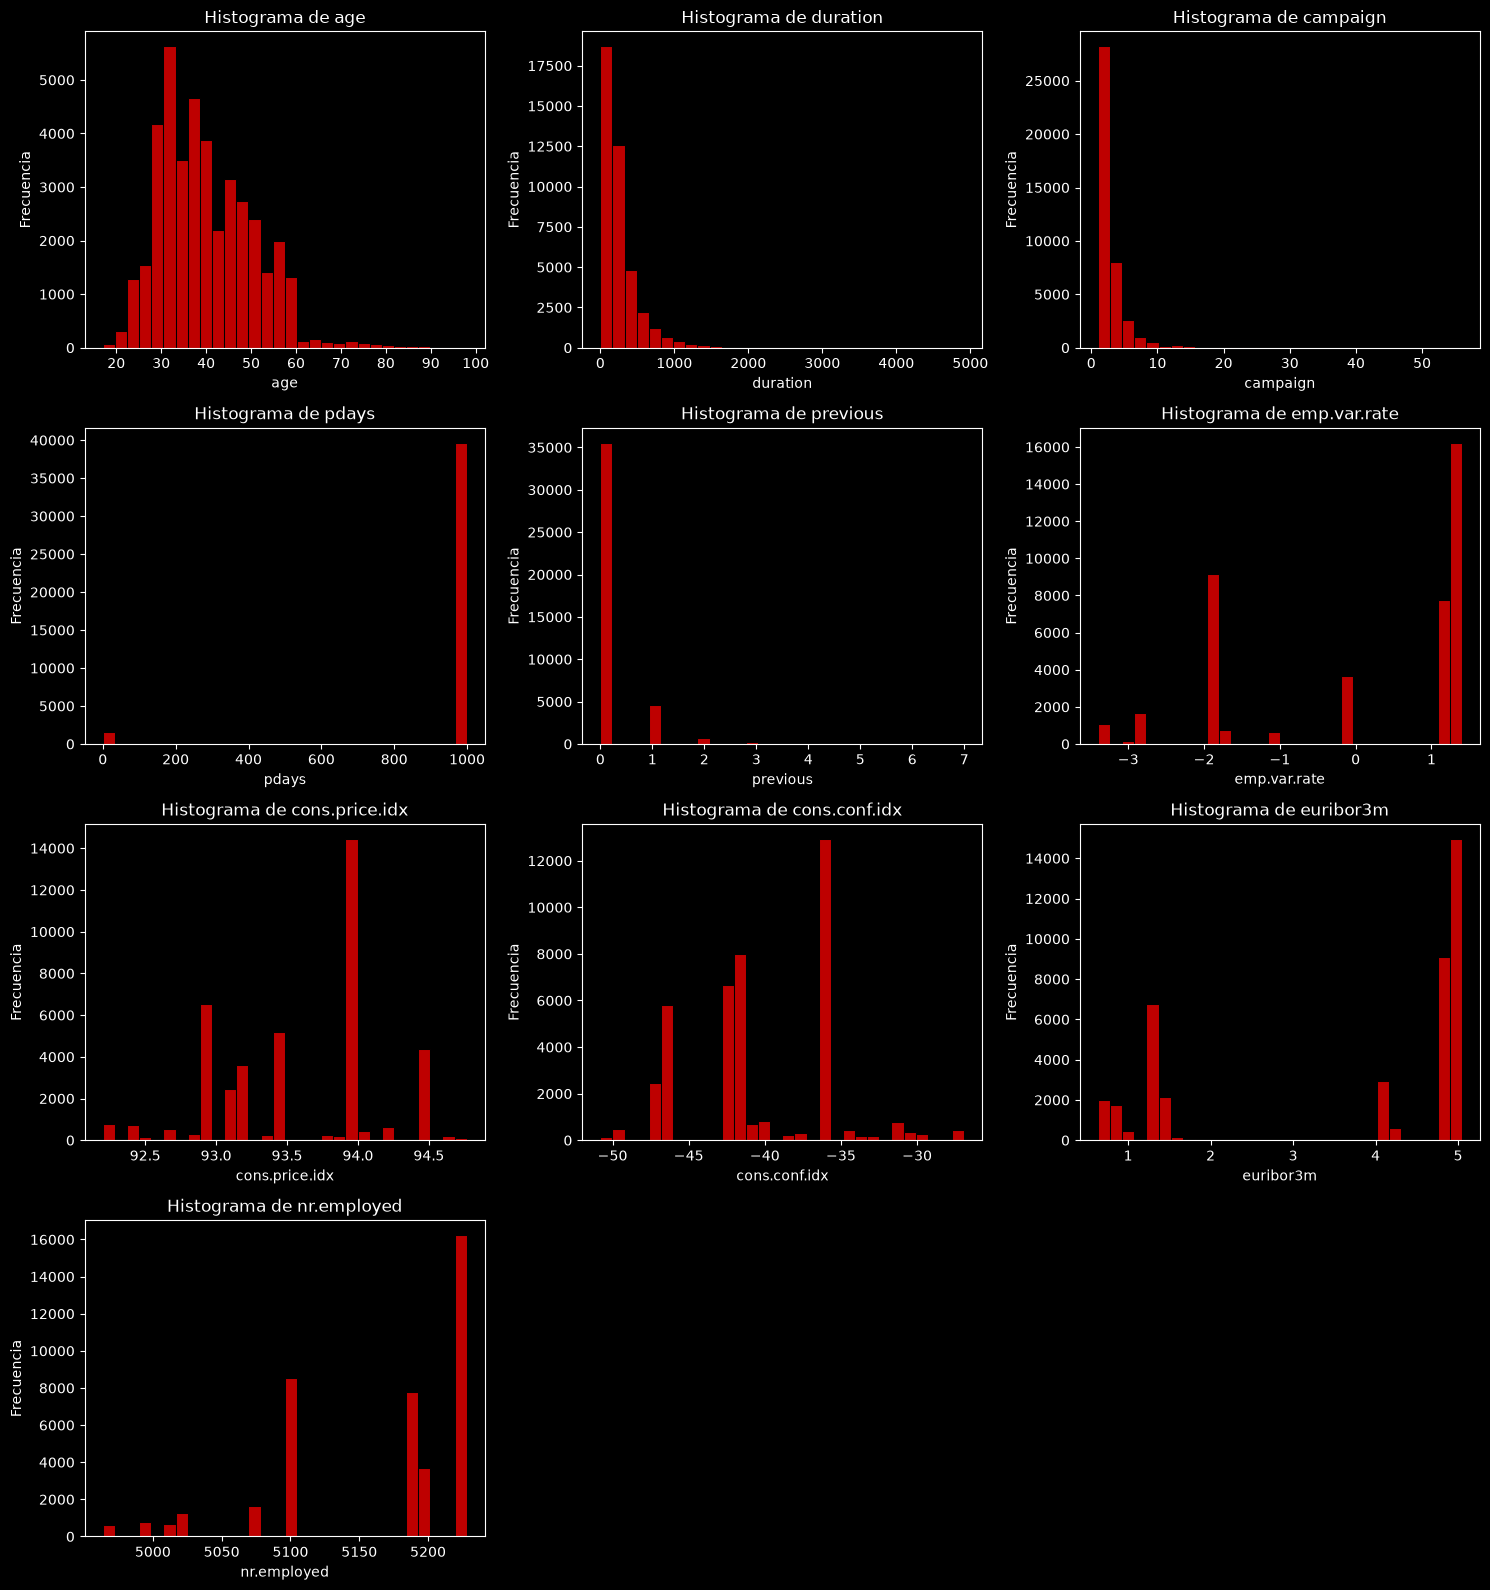

In [45]:
columnas_numericas = bank_df.select_dtypes(include='number').columns.tolist()
estadisticas_numericas(bank_df, columnas_numericas)


Estadisticas para la columna: job
Frecuencia de valores en job:
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64
Valores unicos en job:
['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']
Valores mas frecuentes en job:
0    admin.
Name: job, dtype: object
Valores nulos/faltantes en job: 0 (0.00%)

Estadisticas para la columna: marital
Frecuencia de valores en marital:
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64
Valores unicos en marital:
['married' 'single' 'divorced' 'unknown']
Valores mas frecuentes en marital:
0    married
Name: marital, dtype: object
Valores nulos/faltant

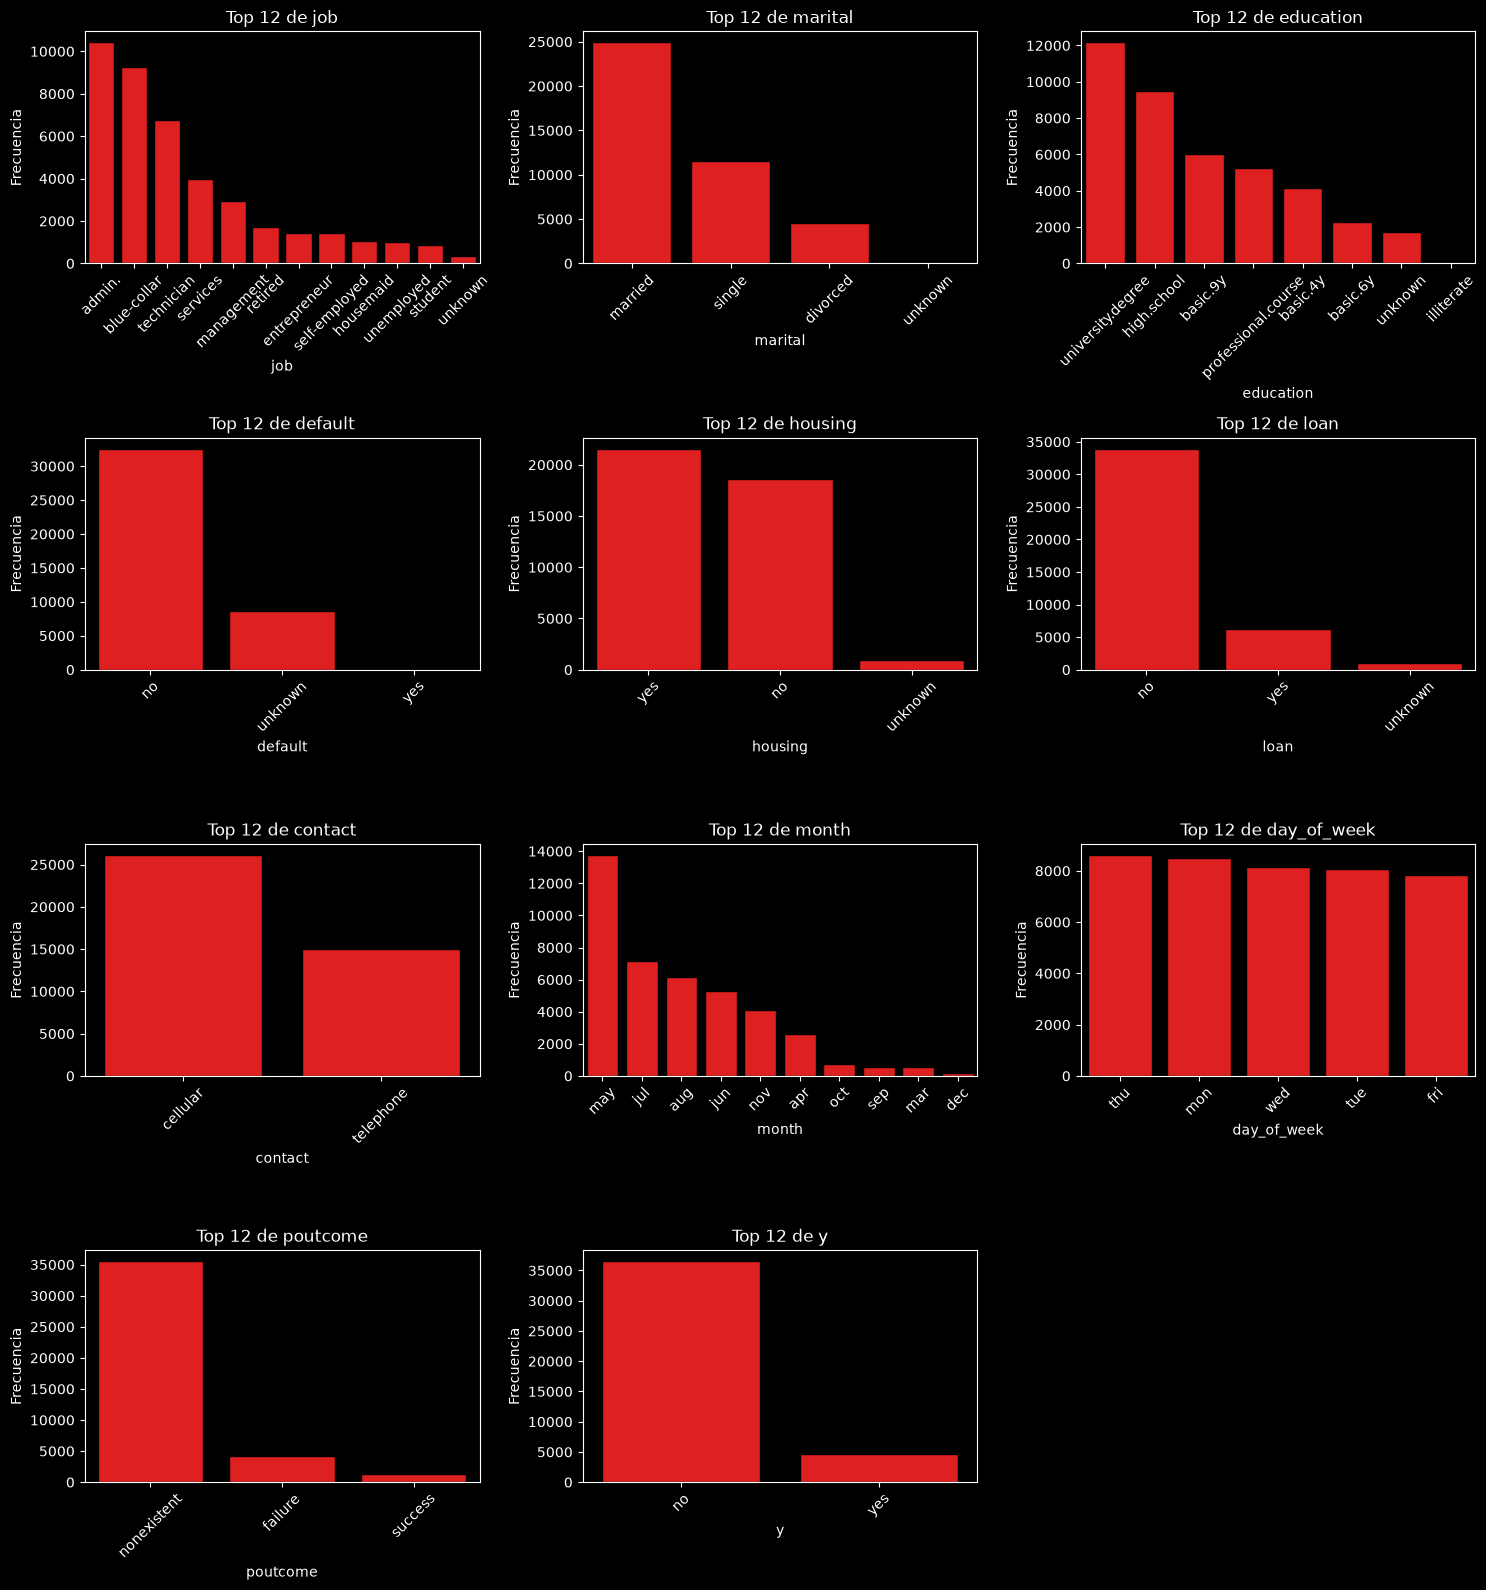

In [46]:
columnas_categoricas = bank_df.select_dtypes(include=['object', 'category']).columns.tolist()
estadisticas_categoricas(bank_df, columnas_categoricas, top_n=12)

In [47]:
# 'unknown' en variables categoricas: no se elimina, se trata como una categoria valida
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome']
for col in cat_cols:
    n_unknown = (bank_df[col] == 'unknown').sum()
    if n_unknown:
        print(f"{col}: {n_unknown} valores 'unknown' ({n_unknown / len(bank_df) * 100:.1f}%)")

job: 330 valores 'unknown' (0.8%)
marital: 80 valores 'unknown' (0.2%)
education: 1731 valores 'unknown' (4.2%)
default: 8597 valores 'unknown' (20.9%)
housing: 990 valores 'unknown' (2.4%)
loan: 990 valores 'unknown' (2.4%)


In [48]:
# 'pdays' usa el valor centinela 999 para indicar "nunca contactado antes"
print((bank_df['pdays'] == 999).mean())
bank_df['pdays'].value_counts().head()

0.9632174419733903


pdays
999    39673
3        439
6        412
4        118
9         64
Name: count, dtype: int64